In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import mplfinance as mpf

In [37]:
crypto = pd.read_csv('/Users/jonas/Documents/GitHub/ZHAW/Semester 5/MLDM/Hackathon/data/crypto_time_series.csv')

# separate after "coin"
btc = crypto[crypto['coin'] == 'BTC']
btc

,date,open,high,low,close,volume,market_cap,coin
0,2018-08-14,6287.66,6287.94,5971.05,6199.71,5.301700e+09,1.081991e+11,BTC
1,2018-08-13,6341.36,6537.05,6225.72,6297.57,4.083980e+09,1.091115e+11,BTC
2,2018-08-12,6283.65,6409.85,6237.50,6322.69,5.665250e+09,1.081065e+11,BTC
3,2018-08-11,6185.79,6455.74,6109.03,6295.73,4.047850e+09,1.064095e+11,BTC
4,2018-08-10,6571.42,6591.26,6124.52,6184.71,4.528680e+09,1.130288e+11,BTC
...,...,...,...,...,...,...,...,...
1930,2013-05-02,116.38,125.60,92.28,105.21,NaN,1.292190e+09,BTC
1931,2013-05-01,139.00,139.89,107.72,116.99,NaN,1.542820e+09,BTC
1932,2013-04-30,144.00,146.93,134.05,139.00,NaN,1.597780e+09,BTC
1933,2013-04-29,134.44,147.49,134.00,144.54,NaN,1.491160e+09,BTC


In [38]:
# Datum in datetime konvertieren
btc['date'] = pd.to_datetime(btc['date'])

# Nach Datum sortieren (wichtig!)
btc = btc.sort_values('date')

# Date-Spalte als Index setzen
btc.set_index('date', inplace=True)

# Spaltennamen für mplfinance richtig setzen
btc = btc.rename(columns={
    'open': 'Open',
    'high': 'High',
    'low': 'Low',
    'close': 'Close'
})

# Candlestick Plot
mpf.plot(btc, type='candle', volume=True, style='yahoo')


/var/folders/br/xflg5m_916s1bn1pdq6h9p3w0000gn/T/ipykernel_12641/3346317975.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  btc['date'] = pd.to_datetime(btc['date'])


ValueError: Column "Volume" NOT FOUND in Input DataFrame!
            CHECK that your column names are correct AND/OR
            CHECK for leading or trailing blanks in your column names.

Index(['date', 'open', 'high', 'low', 'close', 'volume', 'market_cap', 'coin'], dtype='object')


/Users/jonas/miniconda3/envs/MLDM/lib/python3.12/site-packages/mplfinance/_arg_validators.py:84: UserWarning: 


            POSSIBLE TO SEE DETAILS (Candles, Ohlc-Bars, Etc.)
   For more information see:
   - https://github.com/matplotlib/mplfinance/wiki/Plotting-Too-Much-Data
   
   TO SILENCE THIS WARNING, set `type='line'` in `mpf.plot()`
   OR set kwarg `warn_too_much_data=N` where N is an integer 
   LARGER than the number of data points you want to plot.

  warnings.warn('\n\n ================================================================= '+


ValueError: O,H,L,C must have the same amount of missing data!

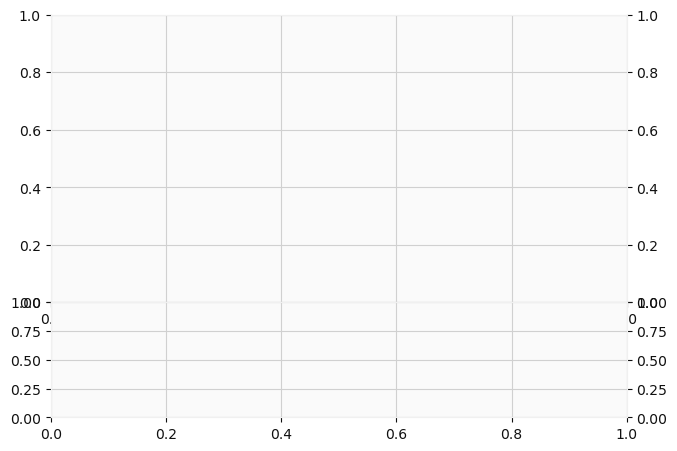

In [19]:
import pandas as pd
import mplfinance as mpf

crypto = pd.read_csv('/Users/jonas/Documents/GitHub/ZHAW/Semester 5/MLDM/Hackathon/data/crypto_time_series.csv')

# Spaltennamen bereinigen
crypto.columns = crypto.columns.str.strip()

# BTC filtern
btc = crypto[crypto['coin'] == 'BTC'].copy()

# prüfen
print(btc.columns)

# Datum umwandeln
btc['date'] = pd.to_datetime(btc['date'])

# sortieren
btc = btc.sort_values('date')

# Index setzen
btc.set_index('date', inplace=True)

# Spalten fuer mplfinance
btc = btc.rename(columns={
    'open': 'Open',
    'high': 'High',
    'low': 'Low',
    'close': 'Close',
    'volume': 'Volume'
})


mpf.plot(btc, type='candle', volume=True, style='yahoo')


In [31]:
btc

,Open,High,Low,Close,Volume,market_cap,coin
date,,,,,,,
2013-12-27,763.28,777.51,713.60,735.07,4.686270e+07,9.295570e+09,BTC
2013-12-28,737.98,747.06,705.35,727.83,3.250580e+07,8.990850e+09,BTC
2013-12-29,728.05,748.61,714.44,745.05,1.901130e+07,8.872600e+09,BTC
2013-12-30,741.35,766.60,740.24,756.13,2.070770e+07,9.037000e+09,BTC
2013-12-31,760.32,760.58,738.17,754.01,2.089730e+07,9.268240e+09,BTC
...,...,...,...,...,...,...,...
2018-08-10,6571.42,6591.26,6124.52,6184.71,4.528680e+09,1.130288e+11,BTC
2018-08-11,6185.79,6455.74,6109.03,6295.73,4.047850e+09,1.064095e+11,BTC
2018-08-12,6283.65,6409.85,6237.50,6322.69,5.665250e+09,1.081065e+11,BTC


In [39]:
print(btc[['Open', 'High', 'Low', 'Close']].isna().sum())


Open     44
High     64
Low      20
Close    68
dtype: int64


In [14]:
btc = btc.dropna(subset=['Open', 'High', 'Low', 'Close', 'Volume'])


In [24]:
fig, axlist = mpf.plot(
    btc,
    type='candle',
    volume=True,
    style='yahoo',
    returnfig=True
)

price_ax = axlist[0]     # first axis is the price axis
price_ax.set_yscale('log')   # <-- set log scale

plt.title('BTC Price')
plt.show()


ValueError: Column "Volume" NOT FOUND in Input DataFrame!
            CHECK that your column names are correct AND/OR
            CHECK for leading or trailing blanks in your column names.

KeyError: 'Unrecognized kwarg="volume_ax"'

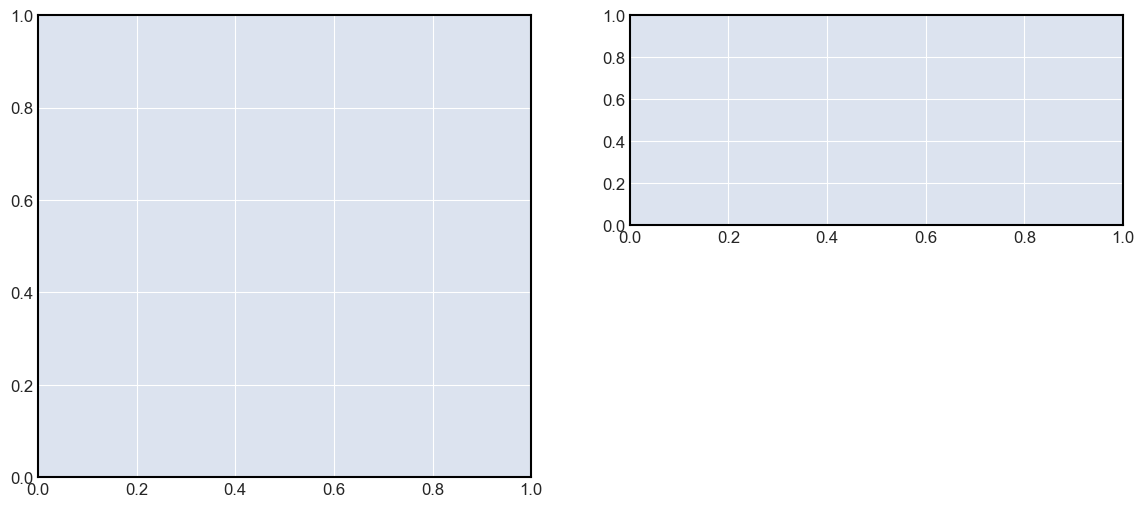

In [25]:
import pandas as pd
import mplfinance as mpf
import matplotlib.pyplot as plt

crypto = pd.read_csv('/Users/jonas/Documents/GitHub/ZHAW/Semester 5/MLDM/Hackathon/data/crypto_time_series.csv')
crypto.columns = crypto.columns.str.strip()

btc = crypto[crypto['coin'] == 'BTC'].copy()
btc['date'] = pd.to_datetime(btc['date'])
btc = btc.sort_values('date')
btc.set_index('date', inplace=True)

btc = btc.rename(columns={
    'open': 'Open',
    'high': 'High',
    'low': 'Low',
    'close': 'Close',
    'volume': 'Volume'
})

btc = btc.dropna(subset=['Open', 'High', 'Low', 'Close', 'Volume'])

# --- Two subplots side by side ---
fig = mpf.figure(figsize=(14, 6))

# Left: linear y-axis
ax_lin  = fig.add_subplot(1, 2, 1)
ax_vol1 = fig.add_subplot(2, 2, 2, sharex=ax_lin)  # volume under linear chart

mpf.plot(
    btc,
    type='candle',
    volume=True,
    style='yahoo',
    ax=ax_lin,
    volume_ax=ax_vol1
)
ax_lin.set_title('BTC Price (Linear Scale)')

# Right: log y-axis
ax_log  = fig.add_subplot(1, 2, 2, sharex=ax_lin)
ax_vol2 = fig.add_subplot(2, 2, 4, sharex=ax_log)  # volume under log chart

mpf.plot(
    btc,
    type='candle',
    volume=True,
    style='yahoo',
    ax=ax_log,
    volume_ax=ax_vol2
)
ax_log.set_yscale('log')
ax_log.set_title('BTC Price (Log Scale)')

plt.tight_layout()
plt.show()

/Users/jonas/miniconda3/envs/MLDM/lib/python3.12/site-packages/mplfinance/_arg_validators.py:84: UserWarning: 


            POSSIBLE TO SEE DETAILS (Candles, Ohlc-Bars, Etc.)
   For more information see:
   - https://github.com/matplotlib/mplfinance/wiki/Plotting-Too-Much-Data
   
   TO SILENCE THIS WARNING, set `type='line'` in `mpf.plot()`
   OR set kwarg `warn_too_much_data=N` where N is an integer 
   LARGER than the number of data points you want to plot.

  warnings.warn('\n\n ================================================================= '+


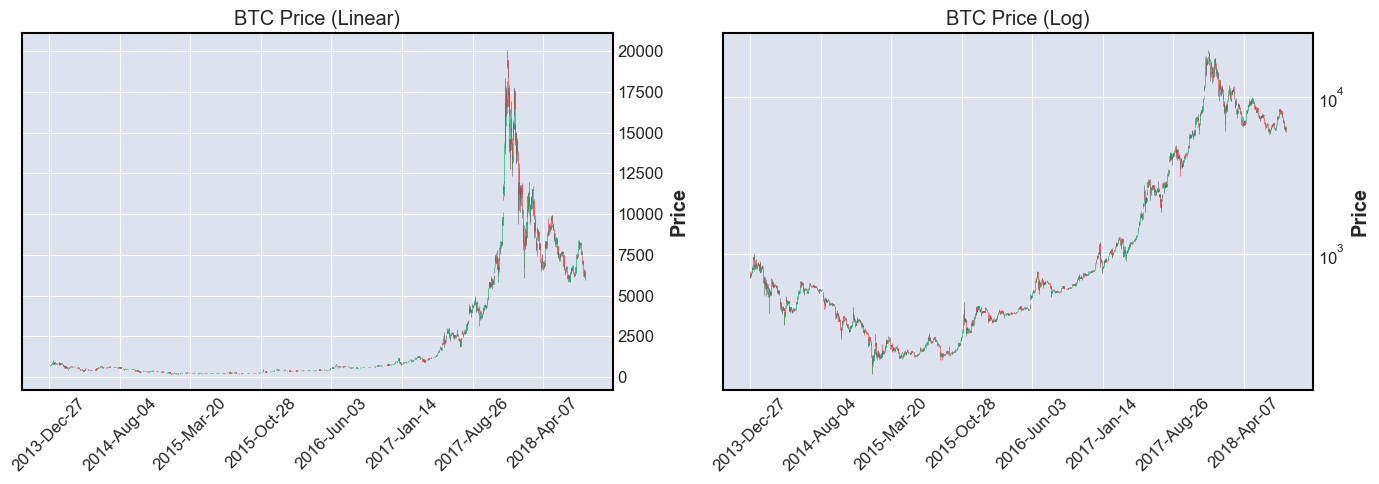

In [26]:
fig, (ax_lin, ax_log) = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

mpf.plot(btc, type='candle', style='yahoo', ax=ax_lin)
ax_lin.set_title('BTC Price (Linear)')

mpf.plot(btc, type='candle', style='yahoo', ax=ax_log)
ax_log.set_yscale('log')
ax_log.set_title('BTC Price (Log)')

plt.tight_layout()
plt.show()

In [29]:
# btc show summary of features (open, high, low, close, volume, market_cap)
btc.describe()

,Open,High,Low,Close,Volume,market_cap
count,1521.000000,1521.000000,1521.000000,1521.000000,1.521000e+03,1.517000e+03
mean,2327.669165,2400.365891,2243.666437,2328.569724,1.459040e+09,3.838787e+10
std,3554.772286,3689.097964,3386.279201,3551.296712,3.180043e+09,6.033400e+10
min,176.900000,211.730000,171.510000,178.100000,4.342080e+06,2.427830e+09
25%,382.420000,390.590000,374.580000,381.650000,2.525880e+07,5.374500e+09
50%,609.740000,615.140000,604.140000,609.890000,6.708530e+07,8.569660e+09
75%,2498.560000,2573.790000,2412.940000,2506.470000,1.064730e+09,4.097130e+10
max,19475.800000,20089.000000,18974.100000,19140.800000,2.384090e+10,3.261413e+11
